In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Windows 设置中文
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

print("✅ 所有库导入成功！")


✅ 所有库导入成功！


In [11]:
# 读取，随机采样10万行，降低内存压力
df = pd.read_csv("UserBehavior.csv")
df.columns = ['user_id', 'item_id', 'category_id', 'behavior_type', 'timestamp']
df = df.sample(n=100000, random_state=42) # random_state固定随机种子，每次采样一样，可复现



In [14]:
df = pd.read_csv("UserBehavior.csv")
df.columns = ['user_id', 'item_id', 'category_id', 'behavior_type', 'timestamp']
df.head()


,user_id,item_id,category_id,behavior_type,timestamp
0,1,2333346,2520771,pv,1511561733
1,1,2576651,149192,pv,1511572885
2,1,3830808,4181361,pv,1511593493
3,1,4365585,2520377,pv,1511596146
4,1,4606018,2735466,pv,1511616481


In [15]:
# 导入时间库
from datetime import datetime

# 把时间戳转为datetime
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')

# 提取日期、小时
df['date'] = df['datetime'].dt.date
df['hour'] = df['datetime'].dt.hour

# 查看时间范围
print("最小时间：", df['datetime'].min())
print("最大时间：", df['datetime'].max())


最小时间： 1902-05-07 22:32:46
最大时间： 2037-04-09 05:22:35


In [13]:
# 设定合法时间区间
start_time = datetime(2017,11,25)
end_time = datetime(2017,12,4)

# 过滤
df = df[(df['datetime'] >= start_time) & (df['datetime'] < end_time)]

# 重置索引
df = df.reset_index(drop=True)

print("过滤后数据行数：", len(df))


过滤后数据行数： 98735


In [16]:
print(df['behavior_type'].value_counts())


pv      89716263
cart     5530446
fav      2888258
buy      2015839
Name: behavior_type, dtype: int64


In [17]:
print(df.isnull().sum())


user_id          0
item_id          0
category_id      0
behavior_type    0
timestamp        0
datetime         0
date             0
hour             0
dtype: int64


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Windows中文设置
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ========== 1.读取 + 随机采样10万条（方案B核心） ==========
# pd.read_csv：读取csv文件
df = pd.read_csv("UserBehavior.csv")
# 给列命名，原始文件没有表头
df.columns = ['user_id', 'item_id', 'category_id', 'behavior_type', 'timestamp']
# sample：随机抽样，n=100000抽10万行；random_state=42固定种子，保证每次抽样一致
df = df.sample(n=100000, random_state=42)

# ========== 2.时间戳转换 ==========
# unit='s'：时间戳单位是秒，转成pandas时间格式
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')
# dt.date：只保留年月日
df['date'] = df['datetime'].dt.date
# dt.hour：提取小时（0~23）
df['hour'] = df['datetime'].dt.hour

# ========== 3.过滤异常时间（只保留业务窗口：2017-11-25 ~ 2017-12-03） ==========
start_time = datetime(2017,11,25)
end_time = datetime(2017,12,4)
# & 代表并且，[]布尔筛选，只保留时间合法数据
df = df[(df['datetime'] >= start_time) & (df['datetime'] < end_time)]
# reset_index：删除旧的断掉的行号，生成连续索引；drop=True 不保留旧索引
df = df.reset_index(drop=True)

print(f"采样+过滤后有效数据量：{len(df)}")
print("=====行为分布=====")
print(df['behavior_type'].value_counts())
print("=====缺失值检查=====")
print(df.isnull().sum())


采样+过滤后有效数据量：98735
=====行为分布=====
pv      88462
cart     5457
fav      2838
buy      1978
Name: behavior_type, dtype: int64
=====缺失值检查=====
user_id          0
item_id          0
category_id      0
behavior_type    0
timestamp        0
datetime         0
date             0
hour             0
dtype: int64


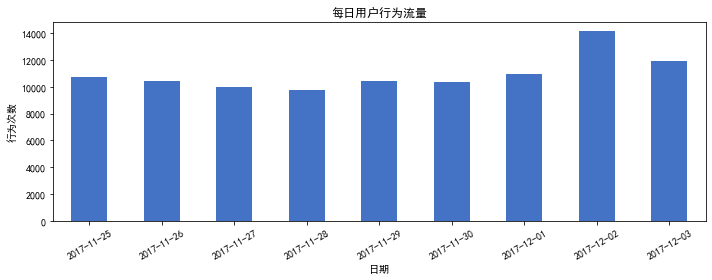

In [3]:
# 按日期分组，统计当天的行为条数
daily_flow = df.groupby('date').size()

# 画图
plt.figure(figsize=(10,4))
daily_flow.plot(kind='bar', color='#4472C4')
plt.title('每日用户行为流量')
plt.xlabel('日期')
plt.ylabel('行为次数')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


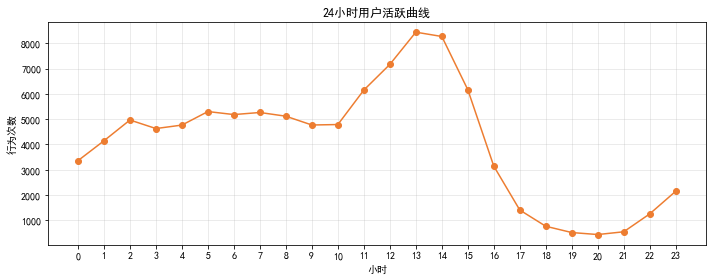

In [4]:
hour_flow = df.groupby('hour').size()
plt.figure(figsize=(10,4))
hour_flow.plot(kind='line', marker='o', color='#ED7D31')
plt.title('24小时用户活跃曲线')
plt.xlabel('小时')
plt.ylabel('行为次数')
plt.xticks(range(0,24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [5]:
# 1. 每个用户，标记他有没有发生过各类行为
user_behavior = df.groupby('user_id')['behavior_type'].agg(lambda x: set(x)).reset_index()

# 定义标记：是否浏览、是否加购、是否收藏、是否购买
user_behavior['is_pv'] = user_behavior['behavior_type'].apply(lambda x: 'pv' in x)
user_behavior['is_cart'] = user_behavior['behavior_type'].apply(lambda x: 'cart' in x)
user_behavior['is_fav'] = user_behavior['behavior_type'].apply(lambda x: 'fav' in x)
user_behavior['is_buy'] = user_behavior['behavior_type'].apply(lambda x: 'buy' in x)

# 统计各环节UV
pv_uv = user_behavior['is_pv'].sum()
cart_uv = user_behavior['is_cart'].sum()
fav_uv = user_behavior['is_fav'].sum()
buy_uv = user_behavior['is_buy'].sum()

print(f"浏览UV：{pv_uv}")
print(f"加购UV：{cart_uv}")
print(f"收藏UV：{fav_uv}")
print(f"下单UV：{buy_uv}")

# 计算转化率
print("-"*30)
print(f"浏览→加购转化率：{cart_uv/pv_uv:.2%}")
print(f"浏览→收藏转化率：{fav_uv/pv_uv:.2%}")
print(f"浏览→下单转化率：{buy_uv/pv_uv:.2%}")
print(f"加购/收藏→下单转化率：{buy_uv/(cart_uv+fav_uv):.2%}")


浏览UV：82060
加购UV：5418
收藏UV：2805
下单UV：1969
------------------------------
浏览→加购转化率：6.60%
浏览→收藏转化率：3.42%
浏览→下单转化率：2.40%
加购/收藏→下单转化率：23.95%


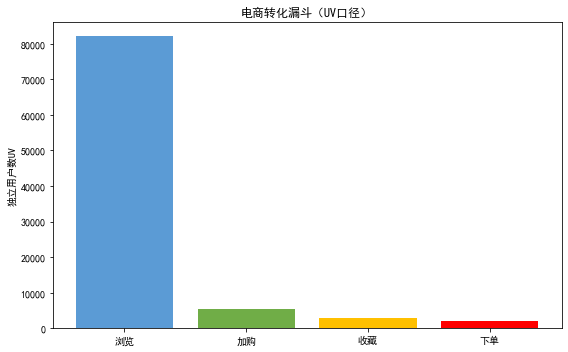

In [6]:
funnel_name = ['浏览', '加购', '收藏', '下单']
funnel_uv = [pv_uv, cart_uv, fav_uv, buy_uv]

plt.figure(figsize=(8,5))
plt.bar(funnel_name, funnel_uv, color=['#5B9BD5','#70AD47','#FFC000','#FF0000'])
plt.title('电商转化漏斗（UV口径）')
plt.ylabel('独立用户数UV')
plt.tight_layout()
plt.show()


In [7]:
# 只保留购买行为的数据
buy_df = df[df['behavior_type'] == 'buy'].copy()
# 每个用户：最后一次购买时间、购买次数
user_rf = buy_df.groupby('user_id').agg(
    last_buy_time = ('datetime','max'),
    buy_freq = ('datetime','count')
).reset_index()

# 取整个数据的最后一天作为参考日期
ref_date = df['datetime'].max()
# R：距离最后一次购买过去了多少天
user_rf['R_days'] = (ref_date - user_rf['last_buy_time']).dt.days

print(user_rf.head())


   user_id       last_buy_time  buy_freq  R_days
0      648 2017-11-27 07:39:52         1       6
1      736 2017-12-02 06:24:17         1       1
2     1574 2017-11-30 06:58:13         1       3
3     1663 2017-12-03 14:15:22         1       0
4     1683 2017-11-28 10:05:17         1       5


高R(近购买)-低频次     1131
低R(久未购买)-低频次     829
低R(久未购买)-高频次       5
高R(近购买)-高频次        4
Name: user_type, dtype: int64


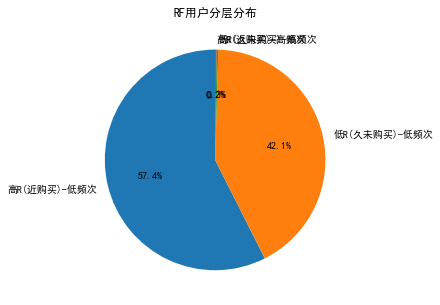

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. R分层（最近购买天数）
user_rf['R_level'] = pd.qcut(
    user_rf['R_days'], 
    q=2, 
    labels=['高R(近购买)','低R(久未购买)'],
    duplicates='drop'
)

# 2. F分层（购买频次，这里改用cut固定阈值，避免qcut报错）
bins_f = [0,1, 100]
labels_f = ['低频次','高频次']
user_rf['F_level'] = pd.cut(user_rf['buy_freq'], bins=bins_f, labels=labels_f, include_lowest=True)

# 3. 组合标签
user_rf['user_type'] = user_rf['R_level'].astype(str) + "-" + user_rf['F_level'].astype(str)

# 统计画图
user_type_count = user_rf['user_type'].value_counts()
print(user_type_count)

plt.figure(figsize=(6,6))
plt.pie(user_type_count, labels=user_type_count.index, autopct='%.1f%%', startangle=90)
plt.title('RF用户分层分布')
plt.tight_layout()
plt.show()


In [9]:
# 统计每个类目下行为数量，看哪些类目热度高
cat_count = df.groupby('category_id').size().sort_values(ascending=False)
print("Top10热门类目：")
print(cat_count.head(10))

# 统计类目转化率：浏览→下单
cat_pv = df[df['behavior_type']=='pv'].groupby('category_id').size()
cat_buy = df[df['behavior_type']=='buy'].groupby('category_id').size()
cat_conv = pd.DataFrame({'pv':cat_pv, 'buy':cat_buy}).fillna(0)
cat_conv['conv_rate'] = cat_conv['buy'] / cat_conv['pv']
print("\n类目转化率Top10")
print(cat_conv.sort_values('conv_rate',ascending=False).head(10))


Top10热门类目：
category_id
4756105    4794
2355072    3348
4145813    3345
3607361    3145
982926     3059
2520377    2249
4801426    2045
1320293    2010
2465336    1666
3002561    1535
dtype: int64

类目转化率Top10
              pv  buy  conv_rate
category_id                     
3681567      0.0  1.0        inf
1352609      0.0  2.0        inf
1406744      0.0  1.0        inf
1442665      0.0  1.0        inf
4705138      0.0  1.0        inf
1628030      0.0  1.0        inf
2626490      0.0  1.0        inf
1734820      0.0  1.0        inf
3759918      0.0  1.0        inf
1753262      0.0  1.0        inf


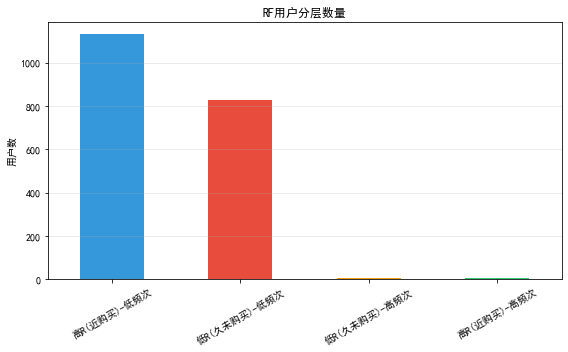

In [10]:
plt.figure(figsize=(8,5))
user_type_count.plot(kind='bar', color=['#3498db','#e74c3c','#f39c12','#2ecc71'])
plt.title('RF用户分层数量')
plt.ylabel('用户数')
plt.xticks(rotation=30)
plt.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:
# 模拟总消费金额：buy_freq * 随机单价，仅练习用，业务上无意义
import numpy as np
np.random.seed(42)
user_rf['total_money'] = user_rf['buy_freq'] * np.random.randint(20,100,size=len(user_rf))


In [12]:
bins_m = [0,50,200,9999]
labels_m = ['低消费','中消费','高消费']
user_rf['M_level'] = pd.cut(user_rf['total_money'], bins=bins_m, labels=labels_m, include_lowest=True)
# 组合R+F+M
user_rf['rfm_type'] = user_rf['R_level'].astype(str)+"-"+user_rf['F_level'].astype(str)+"-"+user_rf['M_level'].astype(str)


In [13]:
# 每个分层的平均消费金额
print(user_rf.groupby('user_type')['total_money'].agg(['mean','count','sum']))


                    mean  count    sum
user_type                             
低R(久未购买)-低频次   58.661037    829  48630
低R(久未购买)-高频次  133.600000      5    668
高R(近购买)-低频次    58.454465   1131  66112
高R(近购买)-高频次   135.500000      4    542


In [14]:
import numpy as np
cat_pv = df[df['behavior_type']=='pv'].groupby('category_id').size()
cat_buy = df[df['behavior_type']=='buy'].groupby('category_id').size()
cat_conv = pd.DataFrame({'pv':cat_pv, 'buy':cat_buy}).fillna(0)
# pv=0时转化率置0，避免无穷大inf
cat_conv['conv_rate'] = np.where(cat_conv['pv']>0, cat_conv['buy']/cat_conv['pv'], 0)
print("\n类目转化率Top10")
print(cat_conv.sort_values('conv_rate',ascending=False).head(10))



类目转化率Top10
              pv  buy  conv_rate
category_id                     
1404020      1.0  5.0        5.0
3211701      1.0  3.0        3.0
194104       2.0  3.0        1.5
2145811      1.0  1.0        1.0
305857       1.0  1.0        1.0
1637260      2.0  2.0        1.0
1673948      1.0  1.0        1.0
3761180      1.0  1.0        1.0
3747679      1.0  1.0        1.0
3554917      1.0  1.0        1.0


浏览：88462
收藏：2838
加购：5457
下单：1978
浏览→收藏转化率：3.21%
浏览→加购转化率：6.17%
加购→下单转化率：36.25%


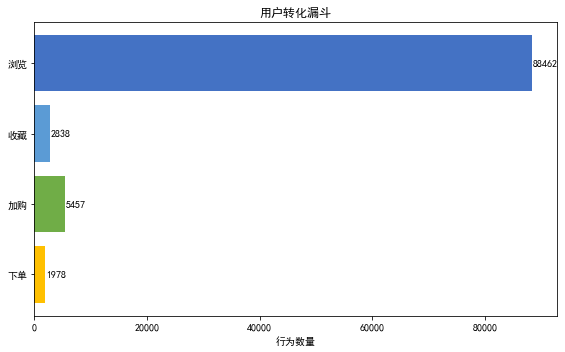

In [15]:
# 漏斗代码
total_pv = len(df[df['behavior_type'] == 'pv'])
total_fav = len(df[df['behavior_type'] == 'fav'])
total_cart = len(df[df['behavior_type'] == 'cart'])
total_buy = len(df[df['behavior_type'] == 'buy'])

print(f"浏览：{total_pv}")
print(f"收藏：{total_fav}")
print(f"加购：{total_cart}")
print(f"下单：{total_buy}")

print(f"浏览→收藏转化率：{total_fav/total_pv:.2%}")
print(f"浏览→加购转化率：{total_cart/total_pv:.2%}")
print(f"加购→下单转化率：{total_buy/(total_cart+1e-6):.2%}") # 加极小值防止除0
import pandas as pd
import matplotlib.pyplot as plt

# 你已经算出的数据
stage = ["浏览","收藏","加购","下单"]
count = [88462, 2838, 5457, 1978]

plt.figure(figsize=(8,5))
bars = plt.barh(stage, count, color=["#4472C4","#5B9BD5","#70AD47","#FFC000"])
plt.gca().invert_yaxis() # 从上往下：浏览→下单
plt.title("用户转化漏斗")
plt.xlabel("行为数量")

# 在柱子上标注数值+转化率
for i,bar in enumerate(bars):
    width = bar.get_width()
    plt.text(width+100, bar.get_y()+bar.get_height()/2, f"{int(width)}", va="center")

plt.tight_layout()
plt.show()


In [18]:
# 统计全部用户的浏览次数（用原始完整df）
user_pv_cnt = df[df['behavior_type'] == 'pv'].groupby('user_id').size().reset_index(name='pv_cnt')
# 统计全部用户加购次数
user_cart_cnt = df[df['behavior_type'] == 'cart'].groupby('user_id').size().reset_index(name='cart_cnt')
# 统计全部用户收藏次数
user_fav_cnt = df[df['behavior_type'] == 'fav'].groupby('user_id').size().reset_index(name='fav_cnt')

# 合并下单表 + 浏览、加购、收藏
user_merge = user_buy_cnt.merge(user_pv_cnt, on='user_id', how='left')\
                         .merge(user_cart_cnt, on='user_id', how='left')\
                         .merge(user_fav_cnt, on='user_id', how='left')

# 缺失值填充为0
user_merge[['pv_cnt','cart_cnt','fav_cnt']] = user_merge[['pv_cnt','cart_cnt','fav_cnt']].fillna(0)

print("===== 用户行为对比 =====")
print("一次性用户：")
print("平均浏览：", user_merge[user_merge['buy_times']==1]['pv_cnt'].mean())
print("平均加购：", user_merge[user_merge['buy_times']==1]['cart_cnt'].mean())
print("平均收藏：", user_merge[user_merge['buy_times']==1]['fav_cnt'].mean())
print("\n复购用户：")
print("平均浏览：", user_merge[user_merge['buy_times']>=2]['pv_cnt'].mean())
print("平均加购：", user_merge[user_merge['buy_times']>=2]['cart_cnt'].mean())
print("平均收藏：", user_merge[user_merge['buy_times']>=2]['fav_cnt'].mean())


===== 用户行为对比 =====
一次性用户：
平均浏览： 0.10714285714285714
平均加购： 0.007653061224489796
平均收藏： 0.004081632653061225

复购用户：
平均浏览： 0.0
平均加购： 0.0
平均收藏： 0.0


In [17]:
# 每个用户总浏览次数
user_pv_cnt = df[df['behavior_type'] == 'pv'].groupby('user_id').size().reset_index(name='pv_cnt')

# 和下单次数表合并
user_merge = pd.merge(user_buy_cnt, user_pv_cnt, on='user_id', how='left')
user_merge['pv_cnt'] = user_merge['pv_cnt'].fillna(0)

print("===== 用户行为对比 =====")
print("一次性用户平均浏览量：", user_merge[user_merge['buy_times']==1]['pv_cnt'].mean())
print("复购用户平均浏览量：", user_merge[user_merge['buy_times']>=2]['pv_cnt'].mean())


===== 用户行为对比 =====
一次性用户平均浏览量： 0.10714285714285714
复购用户平均浏览量： 0.0
